# El Niño in ECMWF's seasonal forecast 🌊
### Copernicus Climate Change Service · SEAS5 · free account

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/unicef/seasonal_elnino.ipynb)

UNICEF's October 2026 El Niño analysis combined **ECMWF's September seasonal forecast** with WorldPop child-population
data. ECMWF issues a new seasonal forecast on the 5th of every month, free through the Copernicus Climate Data Store.
This notebook fetches the latest one and maps what it expects for the coming season: sea-surface temperature, where
El Niño shows itself, and rainfall over land, where children feel it.

*In Google Colab? Press **Runtime → Run all**.*

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes ~1 minute.
!pip install -q "earthkit-data[cds]" earthkit-plots

## Your free Copernicus key

Copernicus data is free and open too, but the data stores ask you to register once so they can manage the queue:
1. Create an account at [cds.climate.copernicus.eu](https://cds.climate.copernicus.eu) (the same login works for the
   Atmosphere Data Store).
2. Open the dataset page and accept its licence (Download tab, bottom of the page). You only do this once.
3. Copy your API key from your [profile page](https://cds.climate.copernicus.eu/profile) and paste it below.
   It is kept only for this Colab session and is not saved in the notebook.

In [2]:
import os
from getpass import getpass
if not os.path.exists(os.path.expanduser("~/.cdsapirc")):
    key = getpass("Copernicus API key: ")
    for url, rc in (("https://cds.climate.copernicus.eu/api", "~/.cdsapirc"),
                    ("https://ads.atmosphere.copernicus.eu/api", "~/.adsapirc")):
        with open(os.path.expanduser(rc), "w") as f:
            f.write(f"url: {url}\nkey: {key}\n")
print("Copernicus key ready")

Copernicus key ready


In [3]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.patheffects as pe
import numpy as np

## 1 · Choose the forecast and the season

`START` is the month the forecast was issued. Lead month 1 is that month, so for a November start, lead months 2, 3
and 4 are December, January and February.

In [4]:
START = "2026-11"
LEADS = [2, 3, 4]                 # December, January, February

## 2 · Get it from the Climate Data Store

The *post-processed* dataset already holds anomalies: the forecast minus ECMWF's own 1993–2016 hindcast climate.

In [5]:
year, month = START.split("-")
seas = ekd.from_source("cds", "seasonal-postprocessed-single-levels", {
    "originating_centre": "ecmwf", "system": "51", "product_type": "ensemble_mean",
    "variable": ["sea_surface_temperature_anomaly", "total_precipitation_anomalous_rate_of_accumulation"],
    "year": year, "month": month, "leadtime_month": [str(m) for m in LEADS], "data_format": "grib"}).to_fieldlist()
ds = seas.to_xarray()
sst = ds["ssta"].mean([d for d in ds["ssta"].dims if d not in ("latitude", "longitude")])
rain = ds["tpara"].mean([d for d in ds["tpara"].dims if d not in ("latitude", "longitude")]) * 86400 * 1000   # m/s -> mm/day
nino34 = float(sst.sel(latitude=slice(5, -5), longitude=slice(190, 240)).mean())
print(f"Niño 3.4 sea-surface temperature anomaly, lead months {LEADS}: {nino34:+.1f} °C")

Niño 3.4 sea-surface temperature anomaly, lead months [2, 3, 4]: +4.0 °C


## 3 · Map the season

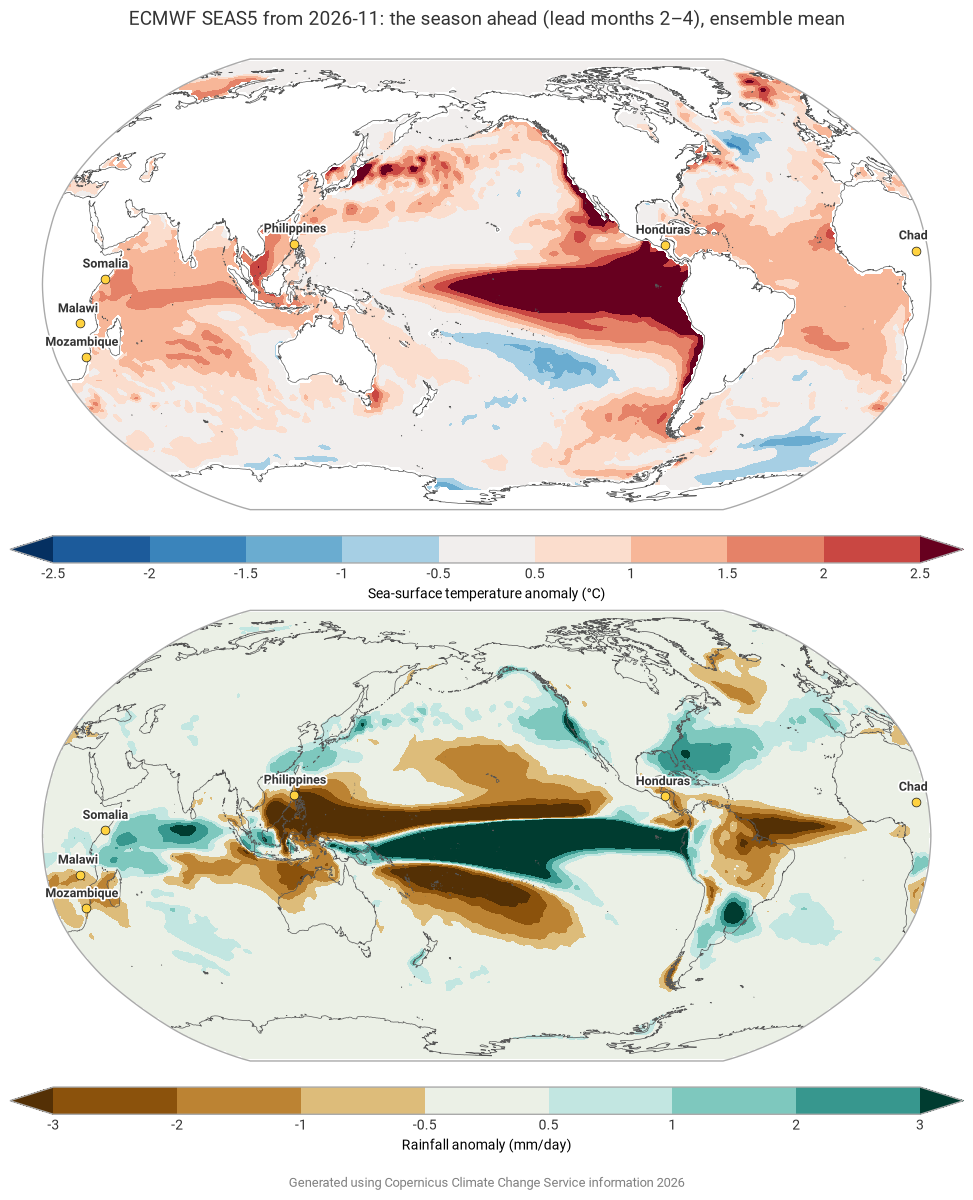

In [6]:
sst_style = ekp.styles.Style(levels=[-2.5, -2, -1.5, -1, -0.5, 0.5, 1, 1.5, 2, 2.5], colors="RdBu_r", extend="both")
rain_style = ekp.styles.Style(levels=[-3, -2, -1, -0.5, 0.5, 1, 2, 3], colors="BrBG", extend="both")
places = [("Somalia", 2.0, 45.3), ("Malawi", -14.0, 33.8), ("Mozambique", -26.0, 32.6),
          ("Philippines", 14.6, 121.0), ("Honduras", 14.1, -87.2), ("Chad", 12.1, 15.1)]

fig = ekp.Figure(rows=2, columns=1, figsize=(12, 11))
for row, (field, style, label) in enumerate(((sst, sst_style, "Sea-surface temperature anomaly (°C)"),
                                              (rain, rain_style, "Rainfall anomaly (mm/day)"))):
    m = fig.add_map(row, 0, crs=ccrs.Robinson(central_longitude=-160))
    m.contourf(field, style=style)
    m.coastlines(linewidth=0.5)
    for name, la, lo in places:
        m.scatter(x=[lo], y=[la], s=40, color="#ffd23f", edgecolors="#1a1a1a", zorder=10)
        m.ax.text(lo, la + 4, name, transform=ccrs.PlateCarree(), ha="center", fontsize=9, fontweight="bold", zorder=11,
                  path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])
    m.legend(label=label)
fig.title(f"ECMWF SEAS5 from {START}: the season ahead (lead months {LEADS[0]}–{LEADS[-1]}), ensemble mean", fontsize=14)
fig.attribution("Generated using Copernicus Climate Change Service information 2026")
fig.save("seasonal_elnino.png")
fig.show()

## 4 · Your turn 🌍

- **Last month's forecast?** Set `START = "2026-09"` to see the run UNICEF used, and compare.
- **Later in the season?** `LEADS = [4, 5, 6]` for February to April.
- **Temperature over land?** Add `"2m_temperature_anomaly"` to the variables (variable `t2a`).
- **Other centres:** the same dataset has forecasts from the UK Met Office, Météo-France, DWD, CMCC and others.

### Data & licence
Copernicus data is free and open under the Copernicus licence (CC-BY 4.0 for these datasets). Credit:
*Generated using Copernicus Climate Change Service / Atmosphere Monitoring Service information [year].*
ECMWF runs both services for the European Union.

[Climate Data Store](https://cds.climate.copernicus.eu) · [Atmosphere Data Store](https://ads.atmosphere.copernicus.eu) ·
[earthkit](https://earthkit.ecmwf.int)